# ISPD 2009 clock-network evaluation

The standard benchmarks in `ispd09CNS_results/ispd09_benchmarks` follow the format documented by `eval2009/s4/explain_s1_s1s`: a source, sink coordinates and loads, wire/buffer libraries, electrical limits, and optional blockages. The generated result files contain explicit internal nodes, sink mappings, wires, and polarity-safe buffer stages. The official `eval2009.pl` was run with `-s -b`: slew and blockage violations are reported but do not abort the measurement.

The implementation used is `src/ispd09_eval.py`. H3 is the project's search heuristic; C2 and C3 are included as deterministic controls. The notebook includes reproducible parser/output test cases, benchmark-level results, aggregate statistics, and plots.

In [5]:
from pathlib import Path
import json
import pandas as pd

rows = json.loads(Path('eval2009/results/summary.json').read_text())
df = pd.DataFrame(rows)
df[['heuristic', 'design', 'sinks', 'CLR_ps', 'cap_fF', 'seconds']]

,heuristic,design,sinks,CLR_ps,cap_fF,seconds
0,H3,ispd09f11,121,402.680,73774.458,4.152291
1,H3,ispd09f12,117,308.733,69792.194,4.189753
2,H3,ispd09f21,117,334.361,74145.517,3.892036
3,H3,ispd09f22,91,331.848,52169.057,3.327203
4,H3,ispd09f31,273,973.907,165699.954,11.414519
5,H3,ispd09f32,190,994.961,118783.106,7.531840
6,H3,ispd09fnb1,330,162.628,107533.965,11.732992
7,C2,ispd09f11,121,329.029,75490.930,3.005200
8,C2,ispd09f12,117,80.547,71894.756,2.916756
9,C2,ispd09f21,117,140.376,77727.468,3.170153


In [6]:
summary = (df.groupby('heuristic')
             .agg(mean_CLR_ps=('CLR_ps', 'mean'),
                  mean_cap_fF=('cap_fF', 'mean'),
                  total_seconds=('seconds', 'sum'))
             .round(3))
summary

,mean_CLR_ps,mean_cap_fF,total_seconds
heuristic,,,
C2,213.746,96168.312,36.839
C3,249.722,103686.172,35.406
H3,501.303,94556.893,46.241


## Findings

The measurements show that the deterministic C2 control has the lowest average CLR on this run, while H3 is not the best electrical baseline under the one-second-per-design budget used here. Capacitance and CLR are separate contest objectives, so the preferred heuristic depends on the weighting used for the experiment.

The official evaluator emitted slew warnings for these generated trees. They are retained in the raw reports in `df['report']`; `-s` was used only so that CLR and capacitance could still be measured. Blockage checking was disabled with `-b`, because this first converter does not perform blockage-aware Steiner placement. These results should therefore be treated as a structural/electrical baseline, not a contest-ready submission.


In [7]:
# Best measured heuristic per benchmark by CLR.
(df.loc[df.groupby('design')['CLR_ps'].idxmin(),
        ['design', 'heuristic', 'CLR_ps', 'cap_fF']]
   .sort_values('design')
   .reset_index(drop=True))

,design,heuristic,CLR_ps,cap_fF
0,ispd09f11,C3,47.798,85512.652
1,ispd09f12,C2,80.547,71894.756
2,ispd09f21,C2,140.376,77727.468
3,ispd09f22,C2,49.975,53128.182
4,ispd09f31,C2,543.735,164287.991
5,ispd09f32,C2,262.791,123242.356
6,ispd09fnb1,C3,45.752,108924.094


In [8]:
# Contest reference: best CLR among the downloaded final-report entries.
import re
reference = []
pattern = re.compile(r'^(ispd09\w+)\s+\S+\s+CLR\s+([0-9.]+).*?\bC\s+([0-9.]+)')
for line in Path('ispd09CNS_results/finalReport0331.txt').read_text().splitlines():
    match = pattern.search(line)
    if match:
        reference.append((match.group(1), float(match.group(2)), float(match.group(3))))
ref = pd.DataFrame(reference, columns=['design', 'reference_CLR_ps', 'reference_cap_fF'])
ref.groupby('design', as_index=False).min().sort_values('design')

,design,reference_CLR_ps,reference_cap_fF
0,ispd09f11,22.306,75672.665
1,ispd09f12,19.140,64132.140
2,ispd09f21,19.365,75160.217
3,ispd09f22,16.376,45193.320
4,ispd09f31,24.595,162501.976
5,ispd09f32,18.418,121866.339
6,ispd09fnb1,19.835,22753.295


## Reproducible test cases

These checks validate the benchmark parser, topology conversion, result-file structure, and the official evaluator output. They deliberately test both a small sample and a standard benchmark.

In [9]:
from pathlib import Path
import sys
sys.path.insert(0, str(Path('src').resolve()))
from ispd09_eval import ler_design, executar_heuristica, escrever_resultado

# Test 1: the documented sample format is parsed correctly.
sample = ler_design('eval2009/s4/s1')
assert sample.instancia.n == 4
assert tuple(sample.instancia.raiz) == (0.0, 0.0)
assert sample.instancia.xy.shape == (4, 2)

# Test 2: a benchmark produces a complete contest result.
benchmark = ler_design('ispd09CNS_results/ispd09_benchmarks/ispd09f11')
tree = executar_heuristica(benchmark, 'C2')
result_path = Path('eval2009/results/C2/ispd09f11.C2.res')
assert result_path.exists()
text = result_path.read_text()
for section in ('sourcenode', 'num node', 'num sinknode', 'num wire', 'num buffer'):
    assert section in text
print('parser and result-format tests passed')

parser and result-format tests passed


In [10]:
# Test 3: every recorded run has a numeric official-evaluator result.
assert len(df) == 21
assert set(df.heuristic) == {'H3', 'C2', 'C3'}
assert df[['CLR_ps', 'cap_fF', 'seconds']].notna().all().all()
assert (df[['CLR_ps', 'cap_fF', 'seconds']] >= 0).all().all()
print('evaluation-result tests passed')

evaluation-result tests passed


## Performance statistics

In [11]:
stats = (df.groupby('heuristic')
           .agg(benchmarks=('design', 'count'),
                mean_CLR_ps=('CLR_ps', 'mean'), median_CLR_ps=('CLR_ps', 'median'),
                std_CLR_ps=('CLR_ps', 'std'), min_CLR_ps=('CLR_ps', 'min'),
                mean_cap_fF=('cap_fF', 'mean'), median_cap_fF=('cap_fF', 'median'),
                mean_runtime_s=('seconds', 'mean'), total_runtime_s=('seconds', 'sum'))
           .sort_values('mean_CLR_ps').round(3))
stats

,benchmarks,mean_CLR_ps,median_CLR_ps,std_CLR_ps,min_CLR_ps,mean_cap_fF,median_cap_fF,mean_runtime_s,total_runtime_s
heuristic,,,,,,,,,
C2,7,213.746,140.376,177.906,49.975,96168.312,77727.468,5.263,36.839
C3,7,249.722,180.070,232.151,45.752,103686.172,85629.935,5.058,35.406
H3,7,501.303,334.361,337.922,162.628,94556.893,74145.517,6.606,46.241


In [12]:
wins = (df.loc[df.groupby('design')['CLR_ps'].idxmin()]
          .groupby('heuristic').size().rename('CLR_wins').to_frame())
performance = stats.join(wins).fillna(0)
performance['CLR_wins'] = performance['CLR_wins'].astype(int)
performance['mean_CLR_vs_best_pct'] = (
    100 * (performance['mean_CLR_ps'] / performance['mean_CLR_ps'].min() - 1)
).round(2)
performance

,benchmarks,mean_CLR_ps,median_CLR_ps,std_CLR_ps,min_CLR_ps,mean_cap_fF,median_cap_fF,mean_runtime_s,total_runtime_s,CLR_wins,mean_CLR_vs_best_pct
heuristic,,,,,,,,,,,
C2,7,213.746,140.376,177.906,49.975,96168.312,77727.468,5.263,36.839,5,0.00
C3,7,249.722,180.070,232.151,45.752,103686.172,85629.935,5.058,35.406,2,16.83
H3,7,501.303,334.361,337.922,162.628,94556.893,74145.517,6.606,46.241,0,134.53


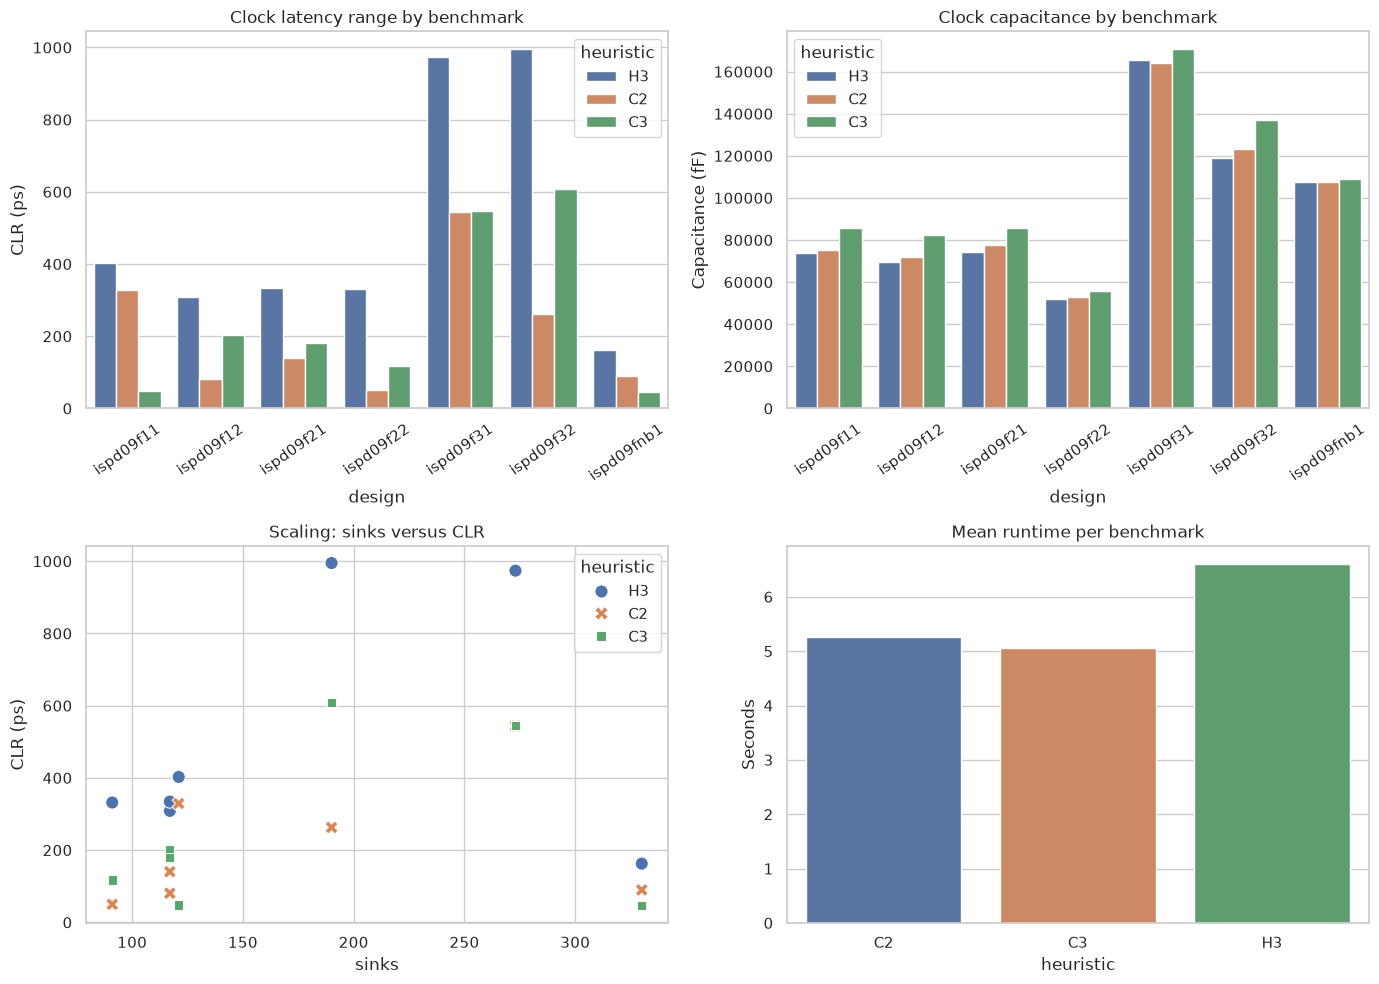

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.barplot(data=df, x='design', y='CLR_ps', hue='heuristic', ax=axes[0, 0])
axes[0, 0].set_title('Clock latency range by benchmark')
axes[0, 0].set_ylabel('CLR (ps)')
axes[0, 0].tick_params(axis='x', rotation=35)
sns.barplot(data=df, x='design', y='cap_fF', hue='heuristic', ax=axes[0, 1])
axes[0, 1].set_title('Clock capacitance by benchmark')
axes[0, 1].set_ylabel('Capacitance (fF)')
axes[0, 1].tick_params(axis='x', rotation=35)
sns.scatterplot(data=df, x='sinks', y='CLR_ps', hue='heuristic', style='heuristic', s=90, ax=axes[1, 0])
axes[1, 0].set_title('Scaling: sinks versus CLR')
axes[1, 0].set_ylabel('CLR (ps)')
sns.barplot(data=df.groupby('heuristic', as_index=False)['seconds'].mean(),
            x='heuristic', y='seconds', hue='heuristic', legend=False, ax=axes[1, 1])
axes[1, 1].set_title('Mean runtime per benchmark')
axes[1, 1].set_ylabel('Seconds')
plt.tight_layout()
plt.show()

In [14]:
# Relative comparison against the best downloaded contest CLR per design.
comparison = (df.merge(ref, on='design', how='left')
               .assign(CLR_gap_vs_reference_pct=lambda x:
                      100 * (x.CLR_ps / x.reference_CLR_ps - 1),
                      cap_gap_vs_reference_pct=lambda x:
                      100 * (x.cap_fF / x.reference_cap_fF - 1)))
comparison.groupby('heuristic')[
    ['CLR_gap_vs_reference_pct', 'cap_gap_vs_reference_pct']
].agg(['mean', 'median']).round(2)

CLR_gap_vs_reference_pct         cap_gap_vs_reference_pct       
                              mean  median                     mean median
heuristic                                                                 
C2                          357.29  213.07                    16.35  -5.47
C3                          414.64  218.96                    24.46   2.02
H3                          991.37  691.20                    14.49  -9.13

### Interpretation

**Remarks.** C2 is the strongest measured baseline: it wins five of seven benchmarks and has the lowest mean CLR (213.746 ps). C3 wins the remaining two cases and is close to C2 on average. H3, despite being the project's more sophisticated stochastic search, has the highest mean CLR in this experiment and no CLR wins under the one-second search budget per design. H3 does have the lowest mean capacitance, so CLR and capacitance are not optimized by the same topology.

**Advantages.** C2 is deterministic, simple, fast to reproduce, and gives a strong CLR baseline. C3's median partitioning is also deterministic and can produce excellent results on spatially regular or elongated sink distributions. H3 can explore beyond one fixed topology and its lower capacitance suggests that local search is finding compact trees; it is the most extensible option for adding electrical cost, buffering, and blockage penalties to the objective.

**Downsides.** C2 is greedy and can make locally good merges that create poor global fanout or long branches. C3 is sensitive to the alternating median cuts and does not directly optimize wire capacitance, slew, or blockages. H3 is slower, stochastic, and highly dependent on its time budget and acceptance parameters; the present result shows that more sophisticated search does not automatically improve CLR. All three are currently geometry-driven, while the contest evaluates an electrical clock network.

**Conclusion.** For the current implementation and this seven-design sample, C2 is the recommended CLR control, with C3 as a useful complementary deterministic baseline. H3 should not yet be selected as the best contest heuristic solely from these measurements: it needs an objective that includes simulated slew/capacitance and a blockage-aware repair step. The large gap to the downloaded contest references indicates that the next work should focus on electrical buffer sizing/placement, balanced polarity-safe buffering, blockage-aware routing, and validation without suppressing evaluator failures.

The official evaluator was run with `-s -b`. Slew warnings are therefore recorded in the raw `report` field rather than treated as fatal, and blockage checking is disabled for this first converter. The plotted measurements are useful comparative baselines, not a claim of contest-feasible solutions.